In [1]:
# ==========================================
# 1. IMPORTING THE LIBRARIES
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

# Importing All Top Regression Models for Comparison
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Importing Regression Evaluation Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

# ==========================================
# 2. LOADING & PREPROCESSING THE DATASET
# ==========================================
# UCI AirQualityUCI.csv uses ';' separator and ',' as decimal
try:
    df = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',')
    if df.shape[1] == 1: # Okavela normal comma separated CSV aithe
        df = pd.read_csv('AirQualityUCI.csv')
except Exception as e:
    print("Error loading file:", e)

# Remove empty unnamed columns and completely empty rows at the end
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]
df.dropna(how='all', inplace=True)

print("Initial Dataset Shape:", df.shape)
print(df.head())

# In UCI Air Quality dataset, missing sensor values are marked as -200
# Replace -200 with NaN (Null)
df.replace(-200, np.nan, inplace=True)
df.replace(-200.0, np.nan, inplace=True)

print("\nMissing values before cleaning (-200 replaced with NaN):")
print(df.isnull().sum())

# Drop column NMHC(GT) because 90% of its data is missing
if 'NMHC(GT)' in df.columns:
    df.drop(columns=['NMHC(GT)'], inplace=True)

# Sort by Date & Time and fill missing values using Forward Fill (Time-Series standard)
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'].str.replace('.', ':', regex=False), dayfirst=True)
df.sort_values('Datetime', inplace=True)
df.ffill(inplace=True)
df.bfill(inplace=True)

print("\nTotal missing values after cleaning:", df.isnull().sum().sum())

Libraries imported successfully.
Initial Dataset Shape: (9357, 15)
         Date      Time  CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  \
0  10/03/2004  18.00.00     2.6       1360.0     150.0      11.9   
1  10/03/2004  19.00.00     2.0       1292.0     112.0       9.4   
2  10/03/2004  20.00.00     2.2       1402.0      88.0       9.0   
3  10/03/2004  21.00.00     2.2       1376.0      80.0       9.2   
4  10/03/2004  22.00.00     1.6       1272.0      51.0       6.5   

   PT08.S2(NMHC)  NOx(GT)  PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)  \
0         1046.0    166.0        1056.0    113.0        1692.0       1268.0   
1          955.0    103.0        1174.0     92.0        1559.0        972.0   
2          939.0    131.0        1140.0    114.0        1555.0       1074.0   
3          948.0    172.0        1092.0    122.0        1584.0       1203.0   
4          836.0    131.0        1205.0    116.0        1490.0       1110.0   

      T    RH      AH  
0  13.6  48.9  0.7578  
1

In [2]:
# ==========================================
# 3. FEATURE ENGINEERING (LAGGED FEATURES)
# ==========================================
# Manam 4 Gases lo edi select chesina run avthundi. 
# Example ki first 'CO(GT)' (Carbon Monoxide) meeda 8 models compare chedham:
target_gas = 'CO(GT)' 

# Creating Lagged Features (Past 1 hour, 2 hours, and 24 hours readings)
df['Lag_1'] = df[target_gas].shift(1)   # 1 hour ago
df['Lag_2'] = df[target_gas].shift(2)   # 2 hours ago
df['Lag_24'] = df[target_gas].shift(24) # Yesterday same time
df['Hour'] = df['Datetime'].dt.hour     # Hour of the day (Traffic peak hours)

# Drop the first 24 rows where Lag_24 is NaN
df_model = df.dropna().copy()

# Selecting Independent Variables (X) - Environmental + Sensors + Lagged Features
feature_cols = [
    'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 
    'PT08.S4(NO2)', 'PT08.S5(O3)', 
    'T', 'RH', 'AH', 
    'Hour', 'Lag_1', 'Lag_2', 'Lag_24'
]

X = df_model[feature_cols]
y = df_model[target_gas]

print("Features Shape (X):", X.shape)
print("Target Shape (y)  :", y.shape)

# ==========================================
# 4. TRAIN-TEST SPLIT (EVALUATE ON FUTURE PERIODS)
# ==========================================
# Problem Statement says: "evaluate on future periods"
# So shuffle=False ensures first 80% (past data) is Train, last 20% (future data) is Test!
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, shuffle=False
)

print("Training data (Past):", X_train.shape)
print("Testing data (Future):", X_test.shape)

# Scaling for Linear, Ridge, Lasso, KNN, SVR (Trees don't need scaling - PDF Page 11)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Features Shape (X): (9333, 12)
Target Shape (y)  : (9333,)
Training data (Past): (7466, 12)
Testing data (Future): (1867, 12)


In [3]:
# ==========================================
# 5. TRAINING & COMPARING ALL 8 MODELS
# ==========================================
models = {
    "Linear Regression": (LinearRegression(), True),
    "Ridge Regression (L2)": (Ridge(alpha=1.0), True),
    "Lasso Regression (L1)": (Lasso(alpha=0.05), True),
    "ElasticNet": (ElasticNet(alpha=0.05, l1_ratio=0.5), True),
    "KNN Regressor": (KNeighborsRegressor(n_neighbors=5), True),
    "SVR (RBF Kernel)": (SVR(C=1.0, epsilon=0.1), True),
    "Decision Tree": (DecisionTreeRegressor(random_state=42), False),
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), False)
}

model_names = []
train_r2_list = []
test_r2_list = []
mae_list = []
mse_list = []
rmse_list = []

for name, (model, needs_scaling) in models.items():
    if needs_scaling:
        model.fit(X_train_scaled, y_train)
        y_train_pred = model.predict(X_train_scaled)
        y_test_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    mae = mean_absolute_error(y_test, y_test_pred)
    mse = mean_squared_error(y_test, y_test_pred)
    rmse = np.sqrt(mse)
    
    model_names.append(name)
    train_r2_list.append(round(train_r2, 4))
    test_r2_list.append(round(test_r2, 4))
    mae_list.append(round(mae, 4))
    mse_list.append(round(mse, 4))
    rmse_list.append(round(rmse, 4))

# Creating Comparison DataFrame (Exact KMIT PDF Page 26 Style)
comparison = pd.DataFrame({
    'Model': model_names,
    'Train R2 Score': train_r2_list,
    'Test R2 Score': test_r2_list,
    'MAE': mae_list,
    'MSE': mse_list,
    'RMSE': rmse_list
})

# Sort by highest Test R2 Score
comparison = comparison.sort_values(by='Test R2 Score', ascending=False).reset_index(drop=True)
print("\n================ FINAL MODEL COMPARISON TABLE ================")
print(comparison)


================ FINAL MODEL COMPARISON TABLE ================
                   Model  Train R2 Score  Test R2 Score     MAE     MSE  \
0          Random Forest          0.9912         0.8540  0.3177  0.2770   
1      Linear Regression          0.8579         0.8484  0.3488  0.2877   
2  Ridge Regression (L2)          0.8579         0.8483  0.3488  0.2877   
3       SVR (RBF Kernel)          0.9292         0.8258  0.3761  0.3304   
4             ElasticNet          0.8480         0.8257  0.3748  0.3307   
5  Lasso Regression (L1)          0.8458         0.8219  0.3769  0.3379   
6          Decision Tree          1.0000         0.7427  0.4439  0.4881   
7          KNN Regressor          0.9402         0.7424  0.4741  0.4886   

     RMSE  
0  0.5263  
1  0.5363  
2  0.5364  
3  0.5748  
4  0.5751  
5  0.5813  
6  0.6987  
7  0.6990  


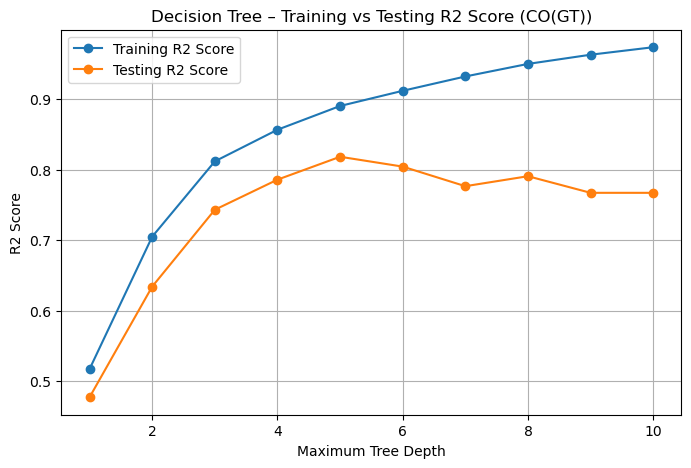

In [4]:
# ==========================================
# 6. DEMONSTRATING OVERFITTING (EFFECT OF MAX_DEPTH)
# ==========================================
depths = range(1, 11)
train_scores = []
test_scores = []

for depth in depths:
    dt_temp = DecisionTreeRegressor(max_depth=depth, random_state=42)
    dt_temp.fit(X_train, y_train)
    train_scores.append(dt_temp.score(X_train, y_train))
    test_scores.append(dt_temp.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker='o', label='Training R2 Score')
plt.plot(depths, test_scores, marker='o', label='Testing R2 Score')
plt.xlabel("Maximum Tree Depth")
plt.ylabel("R2 Score")
plt.title(f"Decision Tree – Training vs Testing R2 Score ({target_gas})")
plt.legend()
plt.grid()
plt.show()